# Reconocimiento de llantas de vehículos por keypoints con YOLO y Detectron2
**IAM-811 Machine Learning y Aprendizaje Profundo** · Ing. Alvaro Pinto Mamani

Los modelos de keypoints preentrenados (COCO) solo conocen el esqueleto humano: **no existe un modelo listo para llantas**. Este notebook resuelve el problema en tres etapas:

| Etapa | Método | Entrenamiento |
|---|---|---|
| 1. Zero-shot | YOLOE-seg (prompts *wheel*, *tire*) → máscara de la llanta → 5 keypoints geométricos | No |
| 2. Auto-etiquetado | El método zero-shot genera un dataset en formato YOLO-pose (corregible en Roboflow) | No |
| 3. Modelos de keypoints | **YOLO-pose** y **Detectron2 Keypoint R-CNN** entrenados con ese dataset | Sí |

**Definición de keypoints (por cada llanta):**

| # | Nombre | Significado |
|---|---|---|
| 0 | centro | centro del aro |
| 1 | contacto | punto de contacto con el suelo |
| 2 | superior | punto más alto de la llanta |
| 3 | izquierda | extremo izquierdo |
| 4 | derecha | extremo derecho |

Las llantas se asocian a cada vehículo (auto, bus, minibús, camión) para contar **llantas visibles** y estimar el **número de ejes**, dato útil para el control de peaje. La estimación de ejes supone vista lateral del vehículo.

**Antes de empezar:** Entorno de ejecución → Cambiar tipo de entorno → **GPU T4**.

## 1. Instalación

In [6]:
!pip install -q ultralytics pyyaml
!nvidia-smi

Wed Nov 25 07:13:42 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   49C    P8             14W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

##google drive y configuracion

In [7]:
from google.colab import drive
from pathlib import Path
import os
import sys
import torch
import ultralytics

drive.mount("/content/drive")

BASE = Path(
    "/content/drive/MyDrive/8vo semestre /Machine learning /PeajeInteligente"
)

assert BASE.is_dir(), "No existe la carpeta del proyecto"

ZIP_M3 = BASE / "datasets/dataset_M3_llantas.zip"

assert ZIP_M3.is_file(), "No se encontró el ZIP del dataset M3"

BEST_M2 = BASE / "modelos/M2_vehiculos/weights/best.pt"

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)
print("CUDA disponible:", torch.cuda.is_available())
print("Modelo M2 encontrado:", BEST_M2.exists())
print("Dataset M3 encontrado:", ZIP_M3.exists())

assert torch.cuda.is_available(), "Activa la GPU T4"

print("GPU:", torch.cuda.get_device_name(0))
print("CONFIGURACIÓN CORRECTA")

Mounted at /content/drive
Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.14.1+cu130
Ultralytics: 8.4.218
CUDA disponible: True
Modelo M2 encontrado: True
Dataset M3 encontrado: True
GPU: Tesla T4
CONFIGURACIÓN CORRECTA


##Preparación del dataset M3

In [8]:
import zipfile
import yaml
from pathlib import Path

RUTA_M3 = Path("/content/dataset_llantas")

RUTA_M3.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(ZIP_M3, "r") as z:
    z.extractall(RUTA_M3)

DATA_YAML = str(RUTA_M3 / "data.yaml")

config = {
    "path": str(RUTA_M3),
    "train": "images/train",
    "val": "images/val",
    "nc": 1,
    "names": {0: "llanta"},
    "kpt_shape": [5, 3],
    "flip_idx": [0, 1, 2, 4, 3]
}

with open(DATA_YAML, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

CONTEO = {}
TOTAL_LLANTAS = 0

for split in ["train", "val"]:

    imagenes = list(
        (RUTA_M3 / "images" / split).glob("*.jpg")
    )

    etiquetas = list(
        (RUTA_M3 / "labels" / split).glob("*.txt")
    )

    assert imagenes, f"No hay imágenes en {split}"

    assert len(imagenes) == len(etiquetas), (
        f"No coinciden imágenes y etiquetas en {split}"
    )

    for imagen in imagenes:

        etiqueta = (
            RUTA_M3 / "labels" / split
            / f"{imagen.stem}.txt"
        )

        assert etiqueta.is_file()

        for linea in etiqueta.read_text().splitlines():

            if linea.strip():

                assert len(linea.split()) == 20, (
                    f"Etiqueta incorrecta: {etiqueta}"
                )

                TOTAL_LLANTAS += 1

    CONTEO[split] = len(imagenes)

    print(split, "- Imágenes:", len(imagenes))
    print(split, "- Etiquetas:", len(etiquetas))

(BASE / "modelos").mkdir(exist_ok=True)
(BASE / "evidencias").mkdir(exist_ok=True)

print("Total de ruedas:", TOTAL_LLANTAS)
print("DATASET M3 LISTO PARA ENTRENAR")

train - Imágenes: 61
train - Etiquetas: 61
val - Imágenes: 9
val - Etiquetas: 9
Total de ruedas: 84
DATASET M3 LISTO PARA ENTRENAR


##Visualización del dataset

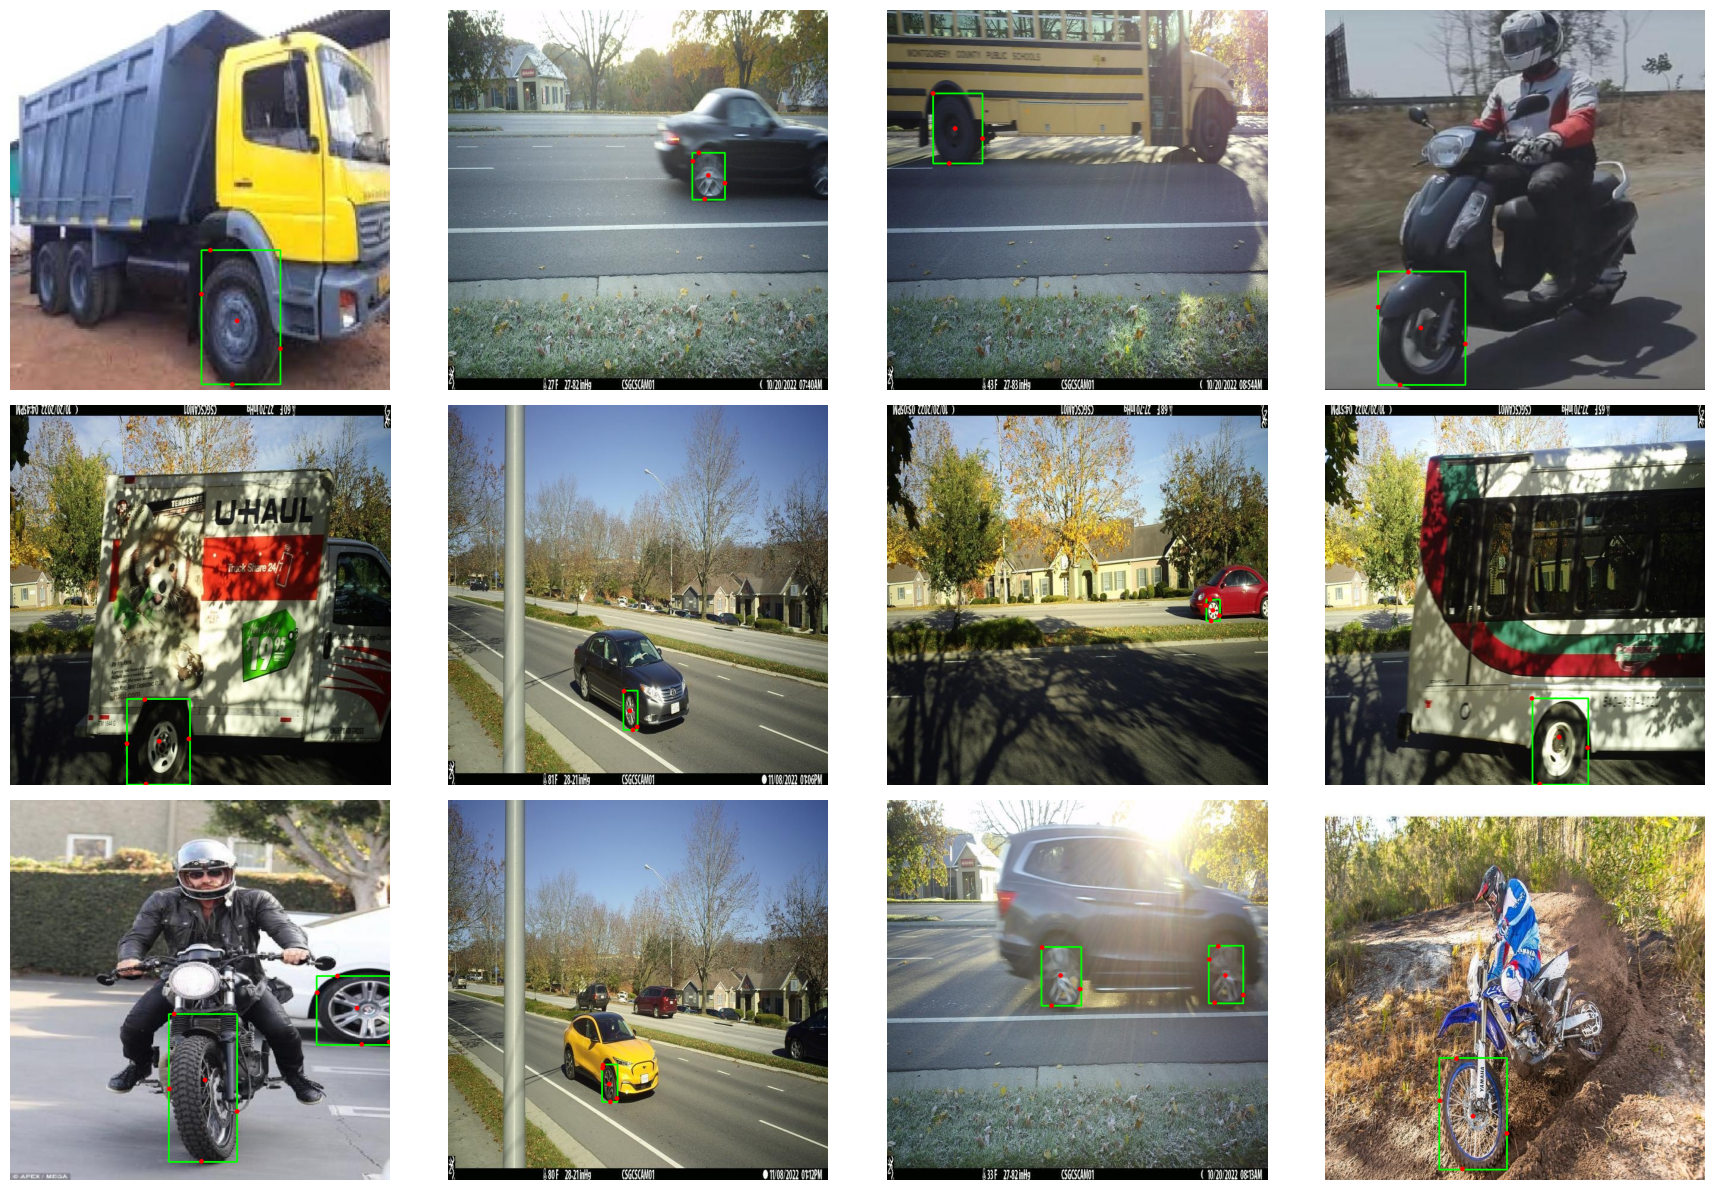

Evidencia guardada correctamente


In [9]:
import cv2
import random
import numpy as np
import matplotlib.pyplot as plt

random.seed(42)

imagenes = list(
    (RUTA_M3 / "images/train").glob("*.jpg")
)

muestra = random.sample(
    imagenes,
    min(12, len(imagenes))
)

fig, axes = plt.subplots(3, 4, figsize=(18, 12))

for ax in axes.flat:
    ax.axis("off")

for ax, ruta in zip(axes.flat, muestra):

    img = cv2.imread(str(ruta))

    if img is None:
        continue

    H, W = img.shape[:2]

    etiqueta = (
        RUTA_M3 / "labels/train"
        / f"{ruta.stem}.txt"
    )

    for linea in etiqueta.read_text().splitlines():

        if not linea.strip():
            continue

        valores = list(map(float, linea.split()))

        _, xc, yc, bw, bh = valores[:5]

        x1 = int((xc - bw / 2) * W)
        y1 = int((yc - bh / 2) * H)
        x2 = int((xc + bw / 2) * W)
        y2 = int((yc + bh / 2) * H)

        cv2.rectangle(
            img,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            2
        )

        puntos = np.array(valores[5:]).reshape(5, 3)

        for x, y, v in puntos:

            if v > 0:

                cv2.circle(
                    img,
                    (int(x * W), int(y * H)),
                    4,
                    (0, 0, 255),
                    -1
                )

    ax.imshow(
        cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    )

plt.tight_layout()

plt.savefig(
    str(BASE / "evidencias/dataset_M3.png"),
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Evidencia guardada correctamente")

##entrenamiento yolo-pose

In [10]:
import gc
import torch
from ultralytics import YOLO

gc.collect()
torch.cuda.empty_cache()

assert torch.cuda.is_available(), "GPU no disponible"

modelo_pose = YOLO("yolo11n-pose.pt")

resultados_m3 = modelo_pose.train(
    data=DATA_YAML,
    epochs=30,
    imgsz=640,
    batch=8,
    device=0,
    workers=2,
    patience=10,
    project=str(BASE / "modelos"),
    name="M3_llantas",
    exist_ok=True,
    pretrained=True,
    plots=True,
    save=True,
    save_period=1,
    amp=True,
    seed=42
)

print("ENTRENAMIENTO M3 FINALIZADO")

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset_llantas/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n-pose.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=M3_llantas, nbs=64, nms=None, opset=None, optimize

##Métricas y almacenamiento de resultados

In [11]:
import json
from ultralytics import YOLO

BEST_M3 = BASE / "modelos/M3_llantas/weights/best.pt"

assert BEST_M3.is_file(), "No se encontraron los pesos"

modelo_final = YOLO(str(BEST_M3))

metricas = modelo_final.val(
    data=DATA_YAML,
    split="val",
    device=0
)

resumen = {
    "modelo": "YOLO11n-pose",
    "imagenes_train": CONTEO["train"],
    "imagenes_val": CONTEO["val"],
    "total_llantas": TOTAL_LLANTAS,
    "precision_pose": float(metricas.pose.mp),
    "recall_pose": float(metricas.pose.mr),
    "map50_pose": float(metricas.pose.map50),
    "map50_95_pose": float(metricas.pose.map),
    "peso_mb": round(
        BEST_M3.stat().st_size / 1024**2, 2
    )
}

print(json.dumps(resumen, indent=4))

with open(
    BASE / "evidencias/metricas_M3.json", "w"
) as f:
    json.dump(resumen, f, indent=4)

print("Modelo guardado en:", BEST_M3)
print("M3 FINALIZADO")

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n-pose summary (fused): 109 layers, 2,654,632 parameters, 0 gradients, 6.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3177.8±742.7 MB/s, size: 118.4 KB)
val: Scanning /content/dataset_llantas/labels/val.cache... 9 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 9/9 2.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Pose(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 7.0it/s 0.1s
                   all          9         13      0.778      0.846      0.801      0.571      0.778      0.846      0.791      0.151
Speed: 0.4ms preprocess, 6.1ms inference, 0.0ms loss, 0.8ms postprocess per image
Results saved to /content/runs/pose/val
{
    "modelo": "YOLO11n-pose",
    "imagenes_train": 61,
    "imagenes_val": 9,
    "total_llantas": 84,
    "precision_pose": 0.7779826079209736,
    "recall_pose": 0.8461538461538461,
 